# Godot gotchas and best practices

**Goal:** get comfortable building a *complete game editor* in Godot, so that as a data dev you make content only in the editor, and as a code dev you only build the mechanism and the tools.

Each gotcha is one row: what bites, a rule of thumb short enough to remember, and the practice behind it.

| Section | Theme | Gotchas |
|---|---|---|
| 1 | Paradigm: complete editor, no code content | 5 |
| 2 | Resources and scenes | 7 |
| 3 | Lifecycle and order | 4 |
| 4 | Building editor tools (`@tool`, `EditorPlugin`) | 6 |
| 5 | Is my editor complete? (checklist) | |
| 6 | How much of my content is still code? (runnable) | |

Deeper explanations live in the companion notebooks in this folder: `godot-instances-and-shared-resources`, `godot-lifecycles`, `godot-editor-as-a-toolbox`, `data-driven-design-in-godot`.


## 1. Paradigm: complete editor, no code content

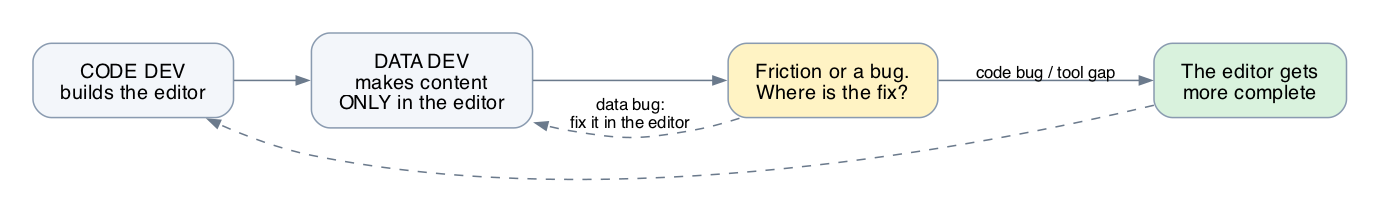

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  code [label="CODE DEV\nbuilds the editor"];
  data [label="DATA DEV\nmakes content\nONLY in the editor"];
  q [label="Friction or a bug.\nWhere is the fix?", fillcolor="#fff3c4"];
  better [label="The editor gets\nmore complete", fillcolor="#d9f2dd"];
  code -> data -> q;
  q -> better [label="code bug / tool gap"];
  q -> data [label="data bug:\nfix it in the editor", style=dashed, constraint=false];
  better -> code [style=dashed, constraint=false];
}
```

</details>

The meta gotcha you already found: **the importance of a complete editor is not obvious until the code content has piled up.**

| # | Gotcha | What bites | Rule of thumb | Best practice |
|---|---|---|---|---|
| P1 | **Code content** | Events written as `await` sequences in scripts. Every new line of dialogue is a code change, and a typo is a code bug | *If making content needs a script open, the editor is incomplete* | Content is data on the Inspector (lambda queues). Code only defines what content *can* do |
| P2 | **The shortcut** | "I'll just script this one event." One becomes thirty | *A tool gap is fixed in the editor, not worked around in content* | When the editor can't express something, add the lambda or field first, then author the content as data |
| P3 | **Silent data bugs** | The editor accepts bad data (an empty slot in a lambda list) and the game fails later | *Fix a data bug twice, then make it impossible or visible* | Typed fields and dropdowns to prevent it, `_get_configuration_warnings()` to flag it |
| P4 | **The editor lies** | The Inspector shows one thing and the game runs another (defaults set in `_init`, or memory differing from disk) | *What the Inspector shows must be what the game runs* | Defaults on the `@export` lines; reload a scene when memory and disk disagree |
| P5 | **Chores done by hand** | The same clicks after placing every event | *Third time by hand, write the tool* | A tool button, an `EditorScript`, or a panel, picked from the ladder in `godot-editor-as-a-toolbox` |

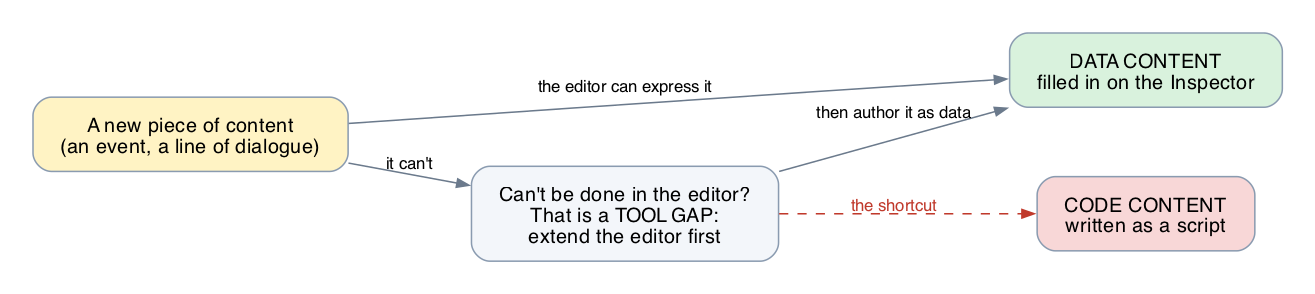

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  need [label="A new piece of content\n(an event, a line of dialogue)", fillcolor="#fff3c4"];
  codec [label="CODE CONTENT\nwritten as a script", fillcolor="#f8d7d7"];
  datac [label="DATA CONTENT\nfilled in on the Inspector", fillcolor="#d9f2dd"];
  gap [label="Can't be done in the editor?\nThat is a TOOL GAP:\nextend the editor first"];
  need -> datac [label="the editor can express it"];
  need -> gap [label="it can't"];
  gap -> datac [label="then author it as data"];
  gap -> codec [label="the shortcut", style=dashed, color="#c0392b", fontcolor="#c0392b"];
}
```

</details>

| Word | Meaning | Fixed by |
|---|---|---|
| Code bug | The mechanism is wrong | Code dev, in a `.gd` file |
| Data bug | The content is wrong | Data dev, in the editor |
| Tool gap | Nothing is wrong, but the editor can't express it or makes it slow | Code dev, by extending the editor |


## 2. Resources and scenes

Your new learning, stated as a rule and then sharpened:

| | |
|---|---|
| **The fact** | A Resource is shared in memory but not on disk: one live object, however many nodes point at it; each file only changes when its own scene is saved |
| **Your rule** | "Never save Resource instances in instantiable base scenes" |
| **Sharpened** | Never save **per-instance data** (lambdas, messages) in an instantiable base scene. Resources that are *meant* to be shared (a texture, a shader, a material) are fine there |
| **In practice** | Leave the lambda list empty in the base scene and fill it on each instance. Lambdas created on the instance are stored in the map file and belong to it |

| # | Gotcha | What bites | Rule of thumb | Best practice |
|---|---|---|---|---|
| R1 | **Shared in memory, not on disk** | Edit a lambda through one instance and every instance, and the base tab, shows the change; the base file does not | *One resource, many pointers* | The sharpened rule above. Or turn on "Local to Scene" on the resource (test it once with two instances first) |
| R2 | **Copies copy nodes, not resources** | Duplicate and Make Local give you new nodes that still point at the old lambda | *Make Unique before you edit* | Right-click the resource in the Inspector, Make Unique, then change it |
| R3 | **IDs are per file** | `Resource_kvxu2` in the base and in the map are different lambdas with the same name | *Trust the path, not the ID* | Hover over a resource in the Inspector to see which file it lives in |
| R4 | **Resources can't hold scene nodes** | A lambda saved in a scene cannot keep a direct reference to a node | *Resources carry paths and names, never nodes* | Export a `NodePath` or a name and look the node up when the lambda runs |
| R5 | **No runtime state on shared resources** | A lambda stores "the current window" on itself; two events share that lambda and overwrite each other | *Resources are settings, not memory* | Keep working values in local variables inside `run()` |
| R6 | **Renaming an exported variable loses its data** | Values are saved under the variable's name. Rename `messages` to `lines` and every saved list is dropped without an error | *A rename is a migration* | Decide names early. For a rename, convert old data with an `EditorScript` before deleting the old name |
| R7 | **Enums are saved as numbers** | Reorder or insert an enum entry and saved content silently points at a different choice | *Number them, never renumber* | Give every enum entry an explicit value and only append |

One more that follows from R1: **overriding a list on an instance replaces the whole list.** There is no per-item diff, so a later change to the base's list will not reach that instance.


## 3. Lifecycle and order

Full detail is in `godot-lifecycles`. These are the ones that hurt editor builders most.

| # | Gotcha | What bites | Rule of thumb | Best practice |
|---|---|---|---|---|
| L1 | **`_init` runs before Inspector values exist** | Reading an exported field in `_init` gives the default, not what you set | *`_init` stores inputs; `_ready` and `run()` use them* | Defaults on the `@export` line. `_init(x_ = null)` only overrides when code passes a value |
| L2 | **The loader calls `_init()` with nothing** | A required `_init` parameter makes every saved object of that class fail to load | *Every `_init` parameter has a default* | Same pattern as L1 |
| L3 | **Setters fire while loading** | An exported setter runs before the node is in the tree, so touching children fails | *Guard setters with `is_node_ready()`* | Do the real work in `_ready`; let the setter just store, or return early until ready |
| L4 | **Suspended does not mean silent** | A suspended scene still receives signals and resumes coroutines; audio keeps playing | *Suspension stops frames, not events* | Gate signal handlers on the scene's active state; stop audio in the finish hook |


## 4. Building editor tools

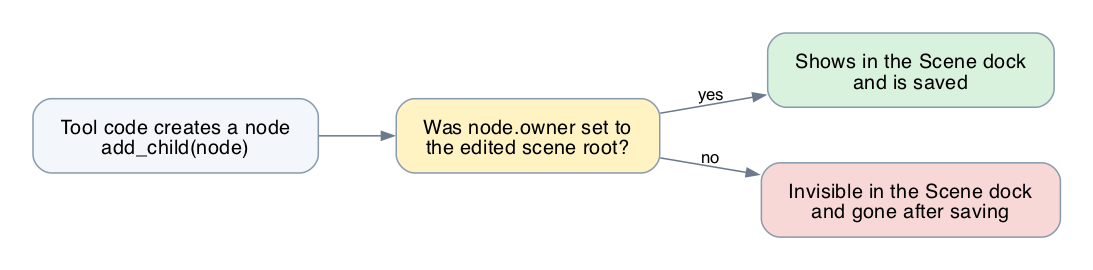

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  make [label="Tool code creates a node\nadd_child(node)"];
  q [label="Was node.owner set to\nthe edited scene root?", fillcolor="#fff3c4"];
  yes [label="Shows in the Scene dock\nand is saved", fillcolor="#d9f2dd"];
  no [label="Invisible in the Scene dock\nand gone after saving", fillcolor="#f8d7d7"];
  make -> q;
  q -> yes [label="yes"];
  q -> no [label="no"];
}
```

</details>

| # | Gotcha | What bites | Rule of thumb | Best practice |
|---|---|---|---|---|
| E1 | **Nodes made by tools vanish** | A tool adds a child; it does not appear in the Scene dock and is gone after saving | *No owner, no save* | After `add_child(node)`, set `node.owner = EditorInterface.get_edited_scene_root()` |
| E2 | **Tool changes skip undo and "unsaved"** | A button changes 40 nodes; Cmd+Z does nothing and the scene may not even be marked as modified | *Every tool edit goes through undo* | Use `EditorUndoRedoManager` (`get_undo_redo()` in a plugin); it gives undo and marks the scene dirty |
| E3 | **`@tool` is all or nothing** | Without it nothing runs in the editor; with it *everything* runs, including game logic that moves or frees nodes in the open scene | *Guard game code with `Engine.is_editor_hint()`* | Keep editor-side code small; anything a `@tool` script calls needs `@tool` too |
| E4 | **Plugins must clean up** | Every reload of the plugin leaves another copy of its panel behind | *Whatever `_enter_tree` adds, `_exit_tree` removes* | Keep a reference to each thing you add and remove it; toggle the plugin off and on after editing its code |
| E5 | **Editor internals are not an API** | A tool that finds editor panels by their internal node names breaks on the next Godot version | *Official hooks only* | `EditorPlugin`, `EditorInterface`, `EditorInspectorPlugin`, `EditorDock`. Print the editor tree to learn, not to depend on |
| E6 | **Editing scene files behind the editor's back** | A `.tscn` changed on disk while open is overwritten on the next save, or the editor shows a stale copy | *One writer at a time* | Close the scene (or Reload Saved Scene) around any text edit of a `.tscn` |

All the method and class names in this section exist in your installed Godot build (checked against the binary).


### Feel it: no owner, no save (E1)

In [1]:
class Node:
	def __init__(self, name): self.name, self.owner, self.children = name, None, []
	def add_child(self, node): self.children.append(node); return node

def save(root):
	"""A scene file only records the root and the nodes it owns."""
	saved, todo = [root.name], list(root.children)
	while todo:
		node = todo.pop(0)
		if node.owner is root: saved.append(node.name)
		todo += node.children
	return saved

scene = Node("Map")

forgot = scene.add_child(Node("EventMadeByTool_A"))          # tool forgot the owner
proper = scene.add_child(Node("EventMadeByTool_B"))
proper.owner = scene                                          # tool set the owner

print("in the tree :", [c.name for c in scene.children])
print("in the file :", save(scene))

in the tree : ['EventMadeByTool_A', 'EventMadeByTool_B']
in the file : ['Map', 'EventMadeByTool_B']


In [2]:
# ----- student scratchpad -----

## 5. Is my editor complete?

"Complete" means the data dev never has a reason to open a script. One row per thing the data dev needs, with the Godot tool that provides it.

| The data dev needs to... | Without it | Provide it with |
|---|---|---|
| Add a new action to an event | Writes a script | A `class_name` Resource per action, in a typed `Array[_RPGM_Lambda]` export |
| Fill in an action's inputs | Guesses types, makes typos | Typed `@export` fields, enums, ranges |
| Point an action at something in the scene | Types a name by hand | `NodePath` export (node picker) |
| See a mistake before running | Finds it by playing | `_get_configuration_warnings()` |
| Do a repeated fix-up | Clicks through it each time | `@export_tool_button`, or a row of buttons via `EditorInspectorPlugin` |
| Preview without running | Runs the game to look | `@tool` on the node |
| See everything at once | Opens events one by one | A dock or bottom panel (`EditorPlugin`) |
| Check all content | Hopes | An `EditorScript` or a Project > Tools menu entry that validates every scene |
| Place a ready-made event | Copies and edits nodes | An instanced scene with Editable Children, lambda list empty in the base |

| When you catch yourself... | It is... | So... |
|---|---|---|
| Opening a script to add content | A tool gap | Add the missing action or field |
| Fixing the same content mistake again | A silent data bug | Add a check |
| Explaining a "you have to remember to..." | A missing guard | Make the editor do it or warn about it |


## 6. How much of my content is still code?

A rough score for gotcha P1. It counts lambda actions only: ones called from scripts (code content) against ones filled in on the Inspector (data content). Read-only.


In [3]:
import os, re

root = os.getcwd()
while not os.path.exists(os.path.join(root, "project.godot")) and root != "/":
	root = os.path.dirname(root)

SKIP = (".godot", "build", "addons", "other", ".artifacts", "assets")
CALL = re.compile(r"run_lambda\(_RPGM_Lambda_")

rows = []
for folder, dirs, names in os.walk(root):
	dirs[:] = [d for d in dirs if os.path.relpath(os.path.join(folder, d), root) not in SKIP]
	for name in names:
		if not name.endswith((".gd", ".tscn")): continue
		path = os.path.join(folder, name)
		text = open(path, errors="ignore").read()
		as_code = len(CALL.findall(text))
		as_data = 0
		if name.endswith(".tscn"):
			lambda_ids = {m.group(2) for m in re.finditer(r'\[ext_resource [^\]]*path="([^"]*)" id="([^"]*)"\]', text) if "/lambdas/" in m.group(1)}
			for block in re.findall(r'\[sub_resource type="Resource"[^\]]*\]\nscript = ExtResource\("([^"]*)"\)', text):
				as_data += block in lambda_ids
		if as_code or as_data: rows.append((os.path.relpath(path, root), as_code, as_data))

print(f"{'file':<68}{'code':>6}{'data':>6}")
for path, as_code, as_data in sorted(rows, key=lambda r: -r[1]):
	print(f"{path:<68}{as_code:>6}{as_data:>6}")
total_code, total_data = sum(r[1] for r in rows), sum(r[2] for r in rows)
print(f"{'TOTAL':<68}{total_code:>6}{total_data:>6}")
if total_code + total_data:
	print(f"\ncontent authored as data: {100 * total_data // (total_code + total_data)}%")

file                                                                  code  data
viewports/rpgm/_RPGM.tscn                                           20     5
viewports/rpgm/common/common_scripts/_rpgm_common_script_teleport.gd     4     0
viewports/rpgm/common/common_scripts/_core_common_change_viewport.gd     2     0
viewports/rpgm/common/common_scripts/_rpgm_common_script_talker.gd       2     0
viewports/rpgm/common/common_events/_common_base_0_0.tscn                0     1
TOTAL                                                                   28     6

content authored as data: 17%


In [4]:
# ----- student scratchpad -----

| Column | Meaning |
|---|---|
| code | Actions run from a script with `run_lambda(...)`: content that needs a code change to edit |
| data | Lambdas stored in a scene: content edited on the Inspector |

Watching the percentage climb is the simplest measure of the editor becoming complete. Each row with a high "code" count is a candidate for the next event to move into a lambda queue.
